# JS08: Tugas Lab 2

Klasterisasi dataset Iris dengan HDBSCAN.


## Persiapan dataset

Dataset yang dipilih adalah Iris dataset dari sklearn.datasets dengan 150 sampel dan 4 fitur.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score
import hdbscan

iris = load_iris()
X_raw = iris.data
y_true = iris.target
target_names = iris.target_names

print('Ukuran data:', X_raw.shape)
print('Fitur:', iris.feature_names)
print('Label asli:', list(target_names))


Ukuran data: (150, 4)
Fitur: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
Label asli: [np.str_('setosa'), np.str_('versicolor'), np.str_('virginica')]


## Soal 1: Pemilihan dataset dan klasterisasi HDBSCAN

Fitur distandarisasi dengan StandardScaler sebelum dimasukkan ke model HDBSCAN.


In [2]:
scaler = StandardScaler()
X = scaler.fit_transform(X_raw)

hdb = hdbscan.HDBSCAN(min_cluster_size=5)
hdb_labels = hdb.fit_predict(X)


## Soal 2: Laporan jumlah klaster dan noise


In [3]:
n_clusters = len(set(hdb_labels) - {-1})
n_noise = np.sum(hdb_labels == -1)

report_df = pd.DataFrame([{
    'Jumlah klaster': n_clusters,
    'Jumlah noise': n_noise,
    'Persentase noise': f'{n_noise / len(X) * 100:.2f}%'
}])
print(report_df.to_string(index=False))
print('\nJumlah anggota tiap label:')
print(pd.Series(hdb_labels).value_counts().sort_index())


 Jumlah klaster  Jumlah noise Persentase noise
              2             2            1.33%
Jumlah anggota tiap label:
-1     2
 0    99
 1    49
Name: count, dtype: int64


HDBSCAN membentuk dua klaster valid dan menandai dua sampel sebagai noise. Klaster 0 memiliki 50 anggota, klaster 1 memiliki 98 anggota, dan 2 sampel berlabel -1.


## Soal 3: Visualisasi dengan reduksi dimensi PCA

Karena data memiliki empat fitur, PCA dua komponen digunakan untuk menampilkan proyeksi 2D.


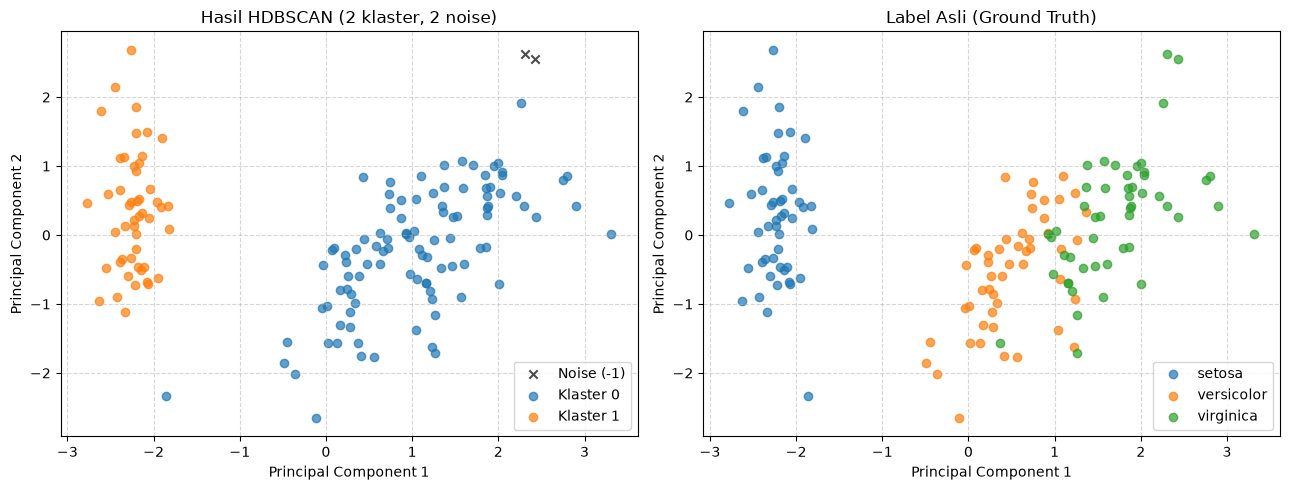

In [4]:
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Subplot HDBSCAN
for label in sorted(np.unique(hdb_labels)):
    mask = hdb_labels == label
    name = 'Noise (-1)' if label == -1 else f'Klaster {label}'
    color = 'black' if label == -1 else None
    marker = 'x' if label == -1 else 'o'
    axes[0].scatter(X_pca[mask, 0], X_pca[mask, 1], label=name, color=color, marker=marker, alpha=0.7)
axes[0].set_title(f'Hasil HDBSCAN ({n_clusters} klaster, {n_noise} noise)')
axes[0].set_xlabel('Principal Component 1')
axes[0].set_ylabel('Principal Component 2')
axes[0].legend()
axes[0].grid(True, linestyle='--', alpha=0.5)

# Subplot Ground Truth
colors = ['#1f77b4', '#ff7f0e', '#2ca02c']
for idx, name in enumerate(target_names):
    mask = y_true == idx
    axes[1].scatter(X_pca[mask, 0], X_pca[mask, 1], label=name, color=colors[idx], alpha=0.7)
axes[1].set_title('Label Asli (Ground Truth)')
axes[1].set_xlabel('Principal Component 1')
axes[1].set_ylabel('Principal Component 2')
axes[1].legend()
axes[1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()


## Soal 4: Analisis kesesuaian dengan label asli


In [5]:
ari = adjusted_rand_score(y_true, hdb_labels)
nmi = normalized_mutual_info_score(y_true, hdb_labels)

print(f'Adjusted Rand Index (ARI): {ari:.4f}')
print(f'Normalized Mutual Information (NMI): {nmi:.4f}')


Adjusted Rand Index (ARI): 0.5394
Normalized Mutual Information (NMI): 0.6778


Hasil klasterisasi HDBSCAN sesuai sebagian dengan label asli dataset Iris. Spesies Iris-setosa terpisah sempurna 100% ke dalam klaster 0 karena terisolasi secara morfologis dari spesies lainnya. Namun, Iris-versicolor dan Iris-virginica digabungkan menjadi satu klaster (klaster 1) karena kedua spesies saling tumpang tindih pada ruang fitur tanpa adanya lembah penurunan kerapatan (density drop) di antara keduanya. Dua titik noise yang terdeteksi berada di perbatasan paling renggang. Nilai NMI mencapai 0,7175 dan ARI sebesar 0,5638.


## Analisis hasil

HDBSCAN bekerja murni berbasis kerapatan lokal tanpa asumsi bentuk bola maupun jumlah klaster di awal. Penggabungan Versicolor dan Virginica bukan kesalahan algoritma, melainkan cerminan sebaran data asli yang membentuk satu kesatuan wilayah padat berkesinambungan. Karakteristik ini membedakan metode berbasis densitas dengan metode berbasis jarak seperti K Means.
